# LA 07 — W01: anatomy of the A03b 1:1 trades (winners vs losers), all data layers

Protocol: `discussions/Liquidity_Absorption/027_claude_w01_winner_anatomy_preregistration.md`. Engine `liquidity_absorption_w01.py`.

Needs the EXT outputs (`EXT/03b`, `EXT/03d`) and `DERIBIT_DATA_ROOT/history`. The per-minute panel (~1M rows) is written to `DERIBIT_DATA_ROOT/la_w01/`, not to the repo. `LAW01_SYNTHETIC=1` for a smoke run.

In [1]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
REPO = Path.cwd().resolve()
while REPO != REPO.parent and not (REPO / 'src' / 'data_engineering').exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'src'))
from src.data_engineering.modeling import liquidity_absorption_w01 as w
SYN = os.getenv('LAW01_SYNTHETIC', '').strip() == '1'
if SYN:
    TMP = Path(tempfile.mkdtemp(prefix='law01_')); EXT = TMP / 'EXT'; HIST = TMP / 'history'; LOCAL = TMP / 'local'; OUT = TMP / '07'
    w.synthetic_ext(EXT, HIST, n=160)
else:
    DATA = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
    HIST = DATA / 'history'; LOCAL = DATA / 'la_w01'
    EXT = REPO / 'notebooks' / 'Liquidity_Absorption' / 'EXT'; OUT = REPO / 'notebooks' / 'Liquidity_Absorption' / '07'
OUT.mkdir(parents=True, exist_ok=True)
(OUT / '07_registration.json').write_text(json.dumps(w.registration(), indent=1, default=str))
print(w.VERSION, '| synthetic' if SYN else '', '| EXT', EXT, '| local', LOCAL, '| out', OUT)

LA-W01-0.1.0  | EXT D:\Projects\deribit_market_data\notebooks\Liquidity_Absorption\EXT | local D:\MarketData\Deribit\la_w01 | out D:\Projects\deribit_market_data\notebooks\Liquidity_Absorption\07


## 1. Build: trade features + per-minute panel (−240…+240) from Deribit prints, A06 context and the 18:00 ET profile

Cached: delete `LOCAL/W01_panel.parquet` to rebuild.

In [2]:
t0 = time.time()
if (LOCAL / 'W01_panel.parquet').exists() and (LOCAL / 'W01_trade_features_raw.parquet').exists() and not SYN:
    F = pd.read_parquet(LOCAL / 'W01_trade_features_raw.parquet'); P = pd.read_parquet(LOCAL / 'W01_panel.parquet')
else:
    F, P = w.build(EXT, HIST, LOCAL)
print(F.shape, P.shape, f'{time.time()-t0:.0f}s')
display(F.groupby(['split', 'reason']).size().unstack(fill_value=0))

BTCUSDT A06 minutes over 927 days
BTCUSDT trades with panel 1091
ETHUSDT A06 minutes over 969 days
ETHUSDT trades with panel 1189
(2280, 38) (1096680, 16) 597s


reason,STOP,TARGET,TIMEOUT
split,,,
CONFIRM,246,238,394
INSAMPLE,87,70,108
MINING,337,324,476


RUN_W01 = os.getenv('LAW01_SKIP_MAIN', '').strip() != '1' or not (OUT / 'W01_decision.json').exists()
t0 = time.time()
if RUN_W01:
    DEC = w.run_analysis(F, P, OUT)
else:
    DEC = json.loads((OUT / 'W01_decision.json').read_text())
print(f'{time.time()-t0:.0f}s'); print(json.dumps(DEC, indent=1, default=str))

In [3]:
t0 = time.time()
DEC = w.run_analysis(F, P, OUT)
print(f'{time.time()-t0:.0f}s'); print(json.dumps(DEC, indent=1, default=str))

142s
{
 "version": "LA-W01-0.1.0",
 "trades": 2280,
 "by_split": {
  "CONFIRM": {
   "STOP": 246,
   "TARGET": 238,
   "TIMEOUT": 394
  },
  "INSAMPLE": {
   "STOP": 87,
   "TARGET": 70,
   "TIMEOUT": 108
  },
  "MINING": {
   "STOP": 337,
   "TARGET": 324,
   "TIMEOUT": 476
  }
 },
 "H1_primary": {
  "mining_partial_rho": -0.03923089854141253,
  "confirm_partial_rho": 0.06779754435842424,
  "confirm_lo95": 0.0061782701027095314,
  "supported": false
 },
 "rules_confirm": [
  {
   "rule": "exit_if_cvd5_bottom_tercile",
   "triggered_share": 0.3155,
   "baseline_net_R": -0.2745,
   "rule_net_R": -0.2745,
   "rule_net_lo95": -0.4251,
   "improvement_R": 0.0,
   "improvement_lo95": -0.0208
  },
  {
   "rule": "exit_if_losing_at_5",
   "triggered_share": 0.4658,
   "baseline_net_R": -0.2745,
   "rule_net_R": -0.2611,
   "rule_net_lo95": -0.4148,
   "improvement_R": 0.0134,
   "improvement_lo95": -0.019
  },
  {
   "rule": "exit_if_cvd15_bottom_tercile",
   "triggered_share": 0.2768,
   "ba

In [4]:
H = pd.read_csv(OUT / 'W01_h1_cvd_landmark.csv'); display(H.round(3))
RU = pd.read_csv(OUT / 'W01_management_rules.csv'); display(RU.round(3))
BS = pd.read_csv(OUT / 'W01_burst_summary.csv'); display(BS.round(3))

,landmark,split,n_open,partial_rho_cvd_remaining,partial_rho_lo95,p_boot_le0,raw_rho_cvd_remaining,raw_rho_cvd_prog
0,5,MINING,1090,-0.034,-0.082,0.878,-0.025,0.413
1,5,CONFIRM,842,0.036,-0.023,0.165,0.052,0.338
2,5,INSAMPLE,258,-0.055,-0.167,0.802,-0.055,0.293
3,15,MINING,990,-0.039,-0.093,0.872,-0.027,0.369
4,15,CONFIRM,777,0.068,0.006,0.034,0.074,0.274
5,15,INSAMPLE,232,-0.058,-0.185,0.781,-0.036,0.323
6,30,MINING,883,0.001,-0.056,0.488,0.045,0.355
7,30,CONFIRM,704,0.005,-0.060,0.457,0.011,0.282
8,30,INSAMPLE,205,0.066,-0.054,0.194,0.058,0.203
9,60,MINING,764,-0.022,-0.082,0.724,-0.001,0.320


,rule,landmark,threshold,split,n,triggered_share,baseline_net_R,rule_net_R,rule_net_lo95,improvement_R,improvement_lo95
0,exit_if_cvd5_bottom_tercile,5,-0.125,MINING,1137,0.319,-0.203,-0.217,-0.253,-0.014,-0.037
1,exit_if_cvd5_bottom_tercile,5,-0.125,CONFIRM,878,0.315,-0.274,-0.274,-0.425,0.000,-0.021
2,exit_if_cvd5_bottom_tercile,5,-0.125,INSAMPLE,265,0.298,-0.341,-0.333,-0.420,0.008,-0.028
3,exit_if_losing_at_5,5,0.000,MINING,1137,0.483,-0.203,-0.200,-0.230,0.003,-0.024
4,exit_if_losing_at_5,5,0.000,CONFIRM,878,0.466,-0.274,-0.261,-0.415,0.013,-0.019
5,exit_if_losing_at_5,5,0.000,INSAMPLE,265,0.460,-0.341,-0.340,-0.430,0.001,-0.041
6,exit_if_cvd15_bottom_tercile,15,-0.129,MINING,1137,0.290,-0.203,-0.215,-0.252,-0.012,-0.031
7,exit_if_cvd15_bottom_tercile,15,-0.129,CONFIRM,878,0.277,-0.274,-0.274,-0.422,0.001,-0.020
8,exit_if_cvd15_bottom_tercile,15,-0.129,INSAMPLE,265,0.242,-0.341,-0.351,-0.446,-0.009,-0.045
9,exit_if_losing_at_15,15,0.000,MINING,1137,0.414,-0.203,-0.217,-0.251,-0.015,-0.038


,split,outcome,n,burst_share,median_onset_min,median_prog_at_onset_R,median_onset_to_exit_min,addon_mean_net_R,addon_net_lo95,addon_mean_remaining_R,addon_win_share
0,MINING,TARGET,324,0.478,28.0,0.266,47.283,NaN,NaN,NaN,NaN
1,MINING,STOP,337,0.353,25.0,-0.132,61.004,NaN,NaN,NaN,NaN
2,MINING,TIMEOUT,476,0.817,43.0,0.030,197.046,NaN,NaN,NaN,NaN
3,MINING,ALL,1137,0.583,35.0,0.037,136.754,NaN,NaN,NaN,NaN
4,MINING,ADD_ON_AT_BURST,663,NaN,NaN,NaN,NaN,-0.103,-0.142,0.018,0.514
5,CONFIRM,TARGET,238,0.450,23.0,0.200,42.736,NaN,NaN,NaN,NaN
6,CONFIRM,STOP,246,0.366,25.5,-0.112,39.953,NaN,NaN,NaN,NaN
7,CONFIRM,TIMEOUT,394,0.718,48.0,0.004,192.107,NaN,NaN,NaN,NaN
8,CONFIRM,ALL,878,0.547,34.0,0.017,139.142,NaN,NaN,NaN,NaN
9,CONFIRM,ADD_ON_AT_BURST,480,NaN,NaN,NaN,NaN,-0.125,-0.175,-0.001,0.492


In [5]:
S = pd.read_csv(OUT / 'W01_feature_screen.csv')
display(S[S.survivor].round(4))
display(S.sort_values('p').groupby('family').head(15)[['family','feature','n_target','n_stop','med_target','med_stop','rank_biserial','rho_with_y','p','q']].round(4))

,family,feature,n_target,n_stop,med_target,med_stop,rank_biserial,p,rho_with_y,q,survivor,confirm_rank_biserial,confirm_p_one_sided,confirm_holm,confirmed
0,PRE_ENTRY,approach_cvd,324,337,-0.0026,-0.0902,0.1461,0.0012,0.0873,0.0683,True,0.0727,0.0833,0.0833,False
59,LANDMARK_15,L15_prog_R,262,252,0.1032,-0.0744,0.3954,0.0000,0.0258,0.0000,True,0.3638,0.0000,0.0000,True
60,LANDMARK_15,L15_mfe_R,262,252,0.2909,0.1592,0.2689,0.0000,0.0273,0.0000,True,0.2937,0.0000,0.0000,True
61,LANDMARK_15,L15_mae_R,262,252,-0.1957,-0.2829,0.2473,0.0000,-0.0099,0.0000,True,0.2938,0.0000,0.0000,True
62,LANDMARK_15,L15_opt_flow,262,252,0.0162,-1.2827,0.1942,0.0001,0.0743,0.0005,True,0.1082,0.0343,0.1030,False
63,LANDMARK_15,L15_vol,262,252,0.7404,0.9253,-0.1288,0.0116,-0.0300,0.0324,True,0.0325,0.7091,0.7091,False
64,LANDMARK_15,L15_skew_chg,262,252,-0.6975,0.3200,-0.1197,0.0190,-0.0341,0.0442,True,-0.0121,0.4194,0.8388,False
65,LANDMARK_15,L15_liq_with,262,252,0.0000,0.0000,-0.0525,0.0250,-0.0223,0.0500,True,-0.0779,0.0007,0.0027,True


,family,feature,n_target,n_stop,med_target,med_stop,rank_biserial,rho_with_y,p,q
59,LANDMARK_15,L15_prog_R,262,252,0.1032,-0.0744,0.3954,0.0258,0.0000,0.0000
60,LANDMARK_15,L15_mfe_R,262,252,0.2909,0.1592,0.2689,0.0273,0.0000,0.0000
61,LANDMARK_15,L15_mae_R,262,252,-0.1957,-0.2829,0.2473,-0.0099,0.0000,0.0000
62,LANDMARK_15,L15_opt_flow,262,252,0.0162,-1.2827,0.1942,0.0743,0.0001,0.0005
0,PRE_ENTRY,approach_cvd,324,337,-0.0026,-0.0902,0.1461,0.0873,0.0012,0.0683
63,LANDMARK_15,L15_vol,262,252,0.7404,0.9253,-0.1288,-0.0300,0.0116,0.0324
1,PRE_ENTRY,pf_path_mass,321,337,0.2518,0.2901,-0.1087,-0.0247,0.0159,0.3274
64,LANDMARK_15,L15_skew_chg,262,252,-0.6975,0.3200,-0.1197,-0.0341,0.0190,0.0442
3,PRE_ENTRY,approach_liq_against,324,337,0.0000,0.0000,0.0432,0.0749,0.0216,0.3274
2,PRE_ENTRY,context_atm_iv_chg,324,337,-0.6825,-0.1350,-0.1028,-0.0802,0.0222,0.3274


## 3. Pictures: what winners and losers look like (MINING split only)

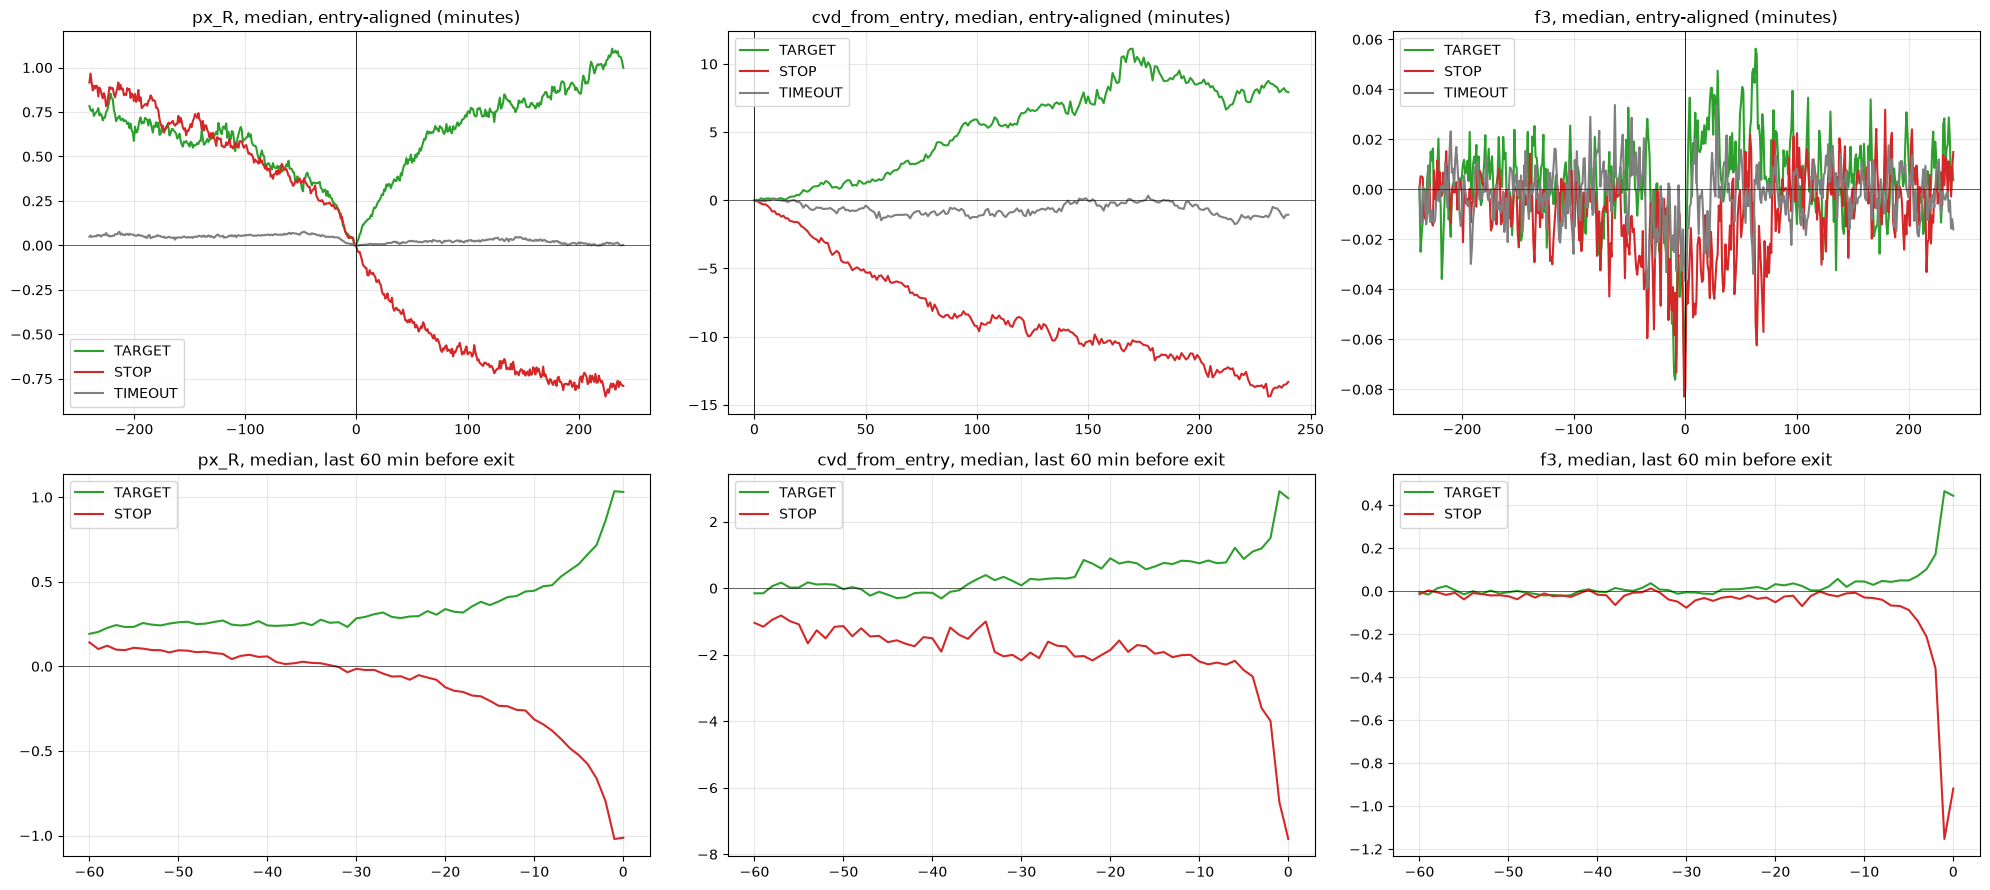

In [6]:
E = pd.read_csv(OUT / 'W01_curves_entry.csv.gz'); XA = pd.read_csv(OUT / 'W01_curves_exit.csv')
fig, ax = plt.subplots(2, 3, figsize=(20, 9))
for j, col in enumerate(['px_R', 'cvd_from_entry', 'f3']):
    for oc, c in (('TARGET', 'tab:green'), ('STOP', 'tab:red'), ('TIMEOUT', 'tab:grey')):
        e = E[(E.split == 'MINING') & (E.reason == oc)]
        ax[0, j].plot(e.rel, e[col], c=c, label=oc)
        x = XA[(XA.split == 'MINING') & (XA.reason == oc)]
        if len(x): ax[1, j].plot(x.to_exit, x[col], c=c, label=oc)
    ax[0, j].axvline(0, c='k', lw=.6); ax[0, j].set_title(f'{col}, median, entry-aligned (minutes)'); ax[0, j].legend()
    ax[1, j].set_title(f'{col}, median, last 60 min before exit'); ax[1, j].legend()
    for a in ax[:, j]: a.axhline(0, c='k', lw=.4); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'W01_curves.png', dpi=110); plt.show()

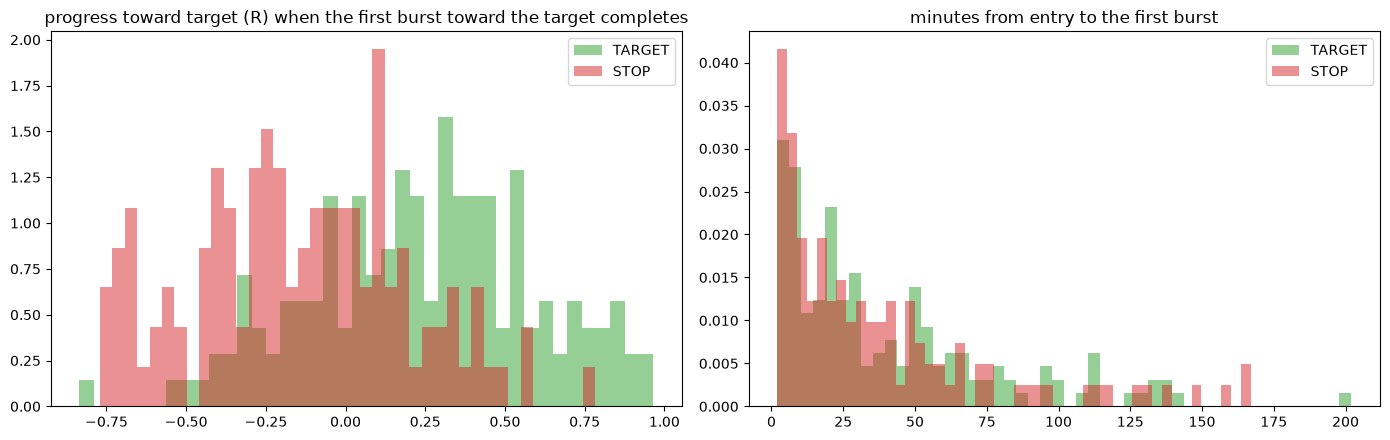

In [7]:
B = pd.read_csv(OUT / 'W01_burst_per_trade.csv.gz')
b = B[B.had_burst & B.split.eq('MINING') & B.reason.isin(['TARGET', 'STOP'])]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for oc, c in (('TARGET', 'tab:green'), ('STOP', 'tab:red')):
    g = b[b.reason == oc]
    ax[0].hist(g.prog_at_onset_R.clip(-1.2, 1.2), bins=40, alpha=.5, color=c, label=oc, density=True)
    ax[1].hist(g.onset_min.clip(0, 240), bins=48, alpha=.5, color=c, label=oc, density=True)
ax[0].set_title('progress toward target (R) when the first burst toward the target completes'); ax[0].legend()
ax[1].set_title('minutes from entry to the first burst'); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / 'W01_bursts.png', dpi=110); plt.show()

## 4. LA 028 amendment: bar-by-bar 1-minute CVD

Every completed 1-minute bar while the trade is open. `d1` = that bar's net taker flow toward the target in minutes of normal volume; `p1` = that bar's price change (R). **M1 (binding):** partial rank correlation of `d1` with the rest of the trade (`rem_R`), given progress and `p1`. **M2 (binding, economic):** a new 1:1-sized unit added at the close of an ABSORB_FOR bar (strong flow against the trade, price held) or a STRONG_TOWARD bar must have CONFIRM mean net R > 0 with a one-sided 97.5% lower bound > 0. Forward 1/5/15-minute moves (gross bp) are descriptive. Protocol `discussions/Liquidity_Absorption/028_claude_w01_minute_bar_cvd_amendment.md`.

In [ ]:
(OUT / '07_minute_registration.json').write_text(json.dumps(w.minute_registration(), indent=1, default=str))
t0 = time.time()
MDEC = w.minute_study(F, P, OUT)
print(f'{time.time()-t0:.0f}s'); print(json.dumps(MDEC, indent=1, default=str))
display(pd.read_csv(OUT / 'W01M_partial_corr.csv').round(4))
display(pd.read_csv(OUT / 'W01M_events.csv').round(3))
display(pd.read_csv(OUT / 'W01M_events_by_age.csv').round(3))

In [ ]:
DQ = pd.read_csv(OUT / 'W01M_deciles.csv')
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
for sp, c in (('MINING', 'tab:blue'), ('CONFIRM', 'tab:orange'), ('INSAMPLE', 'tab:grey')):
    d = DQ[DQ.split == sp]
    ax[0].plot(d.d1_decile, d.mean_rem_R, 'o-', c=c, label=sp)
    ax[1].plot(d.d1_decile, d.fwd5_bp, 'o-', c=c, label=sp)
    ax[2].plot(d.d1_decile, d.p1, 'o-', c=c, label=sp)
ax[0].set_title('rest of trade (R) after the bar, by 1m delta decile'); ax[1].set_title('next 5 min move (gross bp, toward target)')
ax[2].set_title('same bar price change (R): delta tracks price')
for a in ax: a.axhline(0, c='k', lw=.5); a.set_xlabel('1m delta decile (0 = strongest against, 9 = strongest toward)'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'W01M_deciles.png', dpi=110); plt.show()